In [31]:
import sys
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
from matplotlib.colors import ListedColormap 
import sklearn 
from sklearn.tree import (DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text ) 
from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,    cross_validate ) 
from sklearn.metrics import (accuracy_score, ConfusionMatrixDisplay,    classification_report, mean_absolute_error,    mean_squared_error, r2_score ) 
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11}) 
print('Python:', sys.version.split()[0]) 
print('scikit-learn:', sklearn.__version__)

Python: 3.12.13
scikit-learn: 1.7.2


 hours  practice  passed
     1         0       0
     2         1       0
     3         0       0
     4         2       0
     5         1       1
     6         3       0
     7         1       1
     8         4       0
     9         2       1
    10         5       1
    11         3       1
    12         6       1


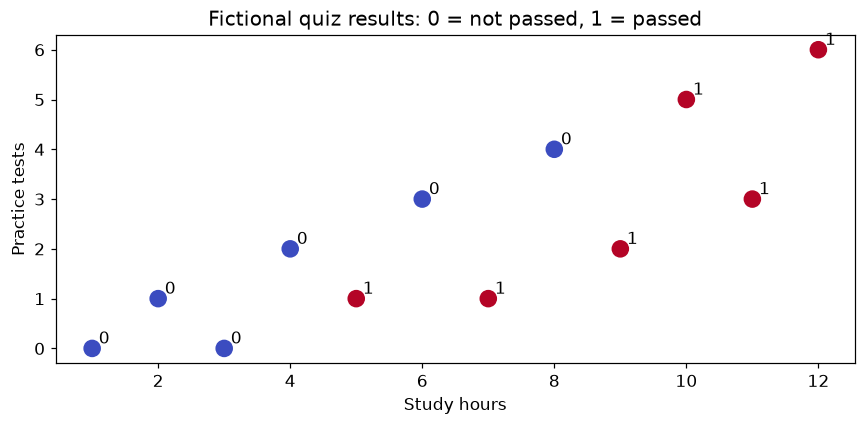

In [32]:
exam = pd.DataFrame({
    'hours': np.arange(1, 13),
    'practice': [0, 1, 0, 2, 1, 3, 1, 4, 2, 5, 3, 6],
    'passed': [0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1]
})

Xe = exam[['hours', 'practice']]
ye = exam['passed']

print(exam.to_string(index=False))

plt.figure(figsize=(8, 4))

plt.scatter(
    Xe.hours,
    Xe.practice,
    c=ye,
    cmap='coolwarm',
    s=110
)

for i in range(len(exam)):
    plt.annotate(
        str(int(ye.iloc[i])),
        (Xe.hours.iloc[i] + 0.1, Xe.practice.iloc[i] + 0.1)
    )

plt.xlabel('Study hours')
plt.ylabel('Practice tests')
plt.title('Fictional quiz results: 0 = not passed, 1 = passed')

plt.tight_layout()
plt.show()

In [33]:
exam['passed'].value_counts()

passed
0    6
1    6
Name: count, dtype: int64

In [34]:
def entropy(prob):
    sur_1 = -prob*(np.log2(prob))
    sur_2 = -(1-prob)*(np.log2(1-prob))
    return sur_1 + sur_2

In [35]:
entropy(0.5)

np.float64(1.0)

In [36]:
entropy(0.9)

np.float64(0.4689955935892811)

C:\Users\AIML\AppData\Local\Temp\ipykernel_54580\1799763350.py:2: RuntimeWarning: divide by zero encountered in log2
  sur_1 = -prob*(np.log2(prob))
C:\Users\AIML\AppData\Local\Temp\ipykernel_54580\1799763350.py:2: RuntimeWarning: invalid value encountered in multiply
  sur_1 = -prob*(np.log2(prob))


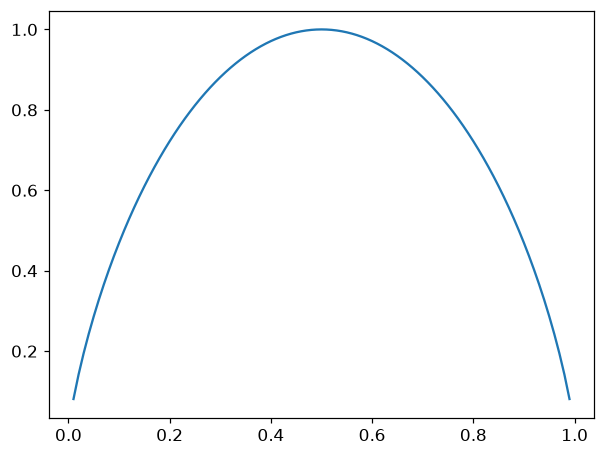

In [37]:
prob_line = np.linspace(0,1,100, endpoint=False)

ent_values = entropy(prob_line)

plt.plot(prob_line, ent_values)

In [38]:
def gini(p):
    return 1 - ((p**2) + ((1-p)**2))


gini(1)

0

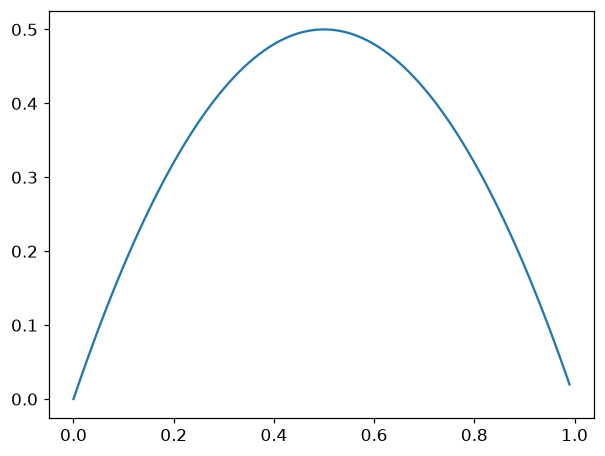

In [39]:
gini_value = gini(prob_line)

plt.plot(prob_line, gini_value)

In [40]:
exam[exam['hours'] <4]['passed'].value_counts()

passed
0    3
Name: count, dtype: int64

In [41]:
gini(1)

0

In [42]:
entropy(0.5)

np.float64(1.0)

In [43]:
entropy(0)

C:\Users\AIML\AppData\Local\Temp\ipykernel_54580\1799763350.py:2: RuntimeWarning: divide by zero encountered in log2
  sur_1 = -prob*(np.log2(prob))
C:\Users\AIML\AppData\Local\Temp\ipykernel_54580\1799763350.py:2: RuntimeWarning: invalid value encountered in scalar multiply
  sur_1 = -prob*(np.log2(prob))


np.float64(nan)

In [44]:
gini(0.6)

0.48

In [45]:
gini(0.4)

0.48

In [46]:
gini(0.8)

0.31999999999999984

In [47]:
entropy(0)

C:\Users\AIML\AppData\Local\Temp\ipykernel_54580\1799763350.py:2: RuntimeWarning: divide by zero encountered in log2
  sur_1 = -prob*(np.log2(prob))
C:\Users\AIML\AppData\Local\Temp\ipykernel_54580\1799763350.py:2: RuntimeWarning: invalid value encountered in scalar multiply
  sur_1 = -prob*(np.log2(prob))


np.float64(nan)

In [48]:
entropy(0.8)

np.float64(0.7219280948873623)

In [49]:
entropy(0.4)

np.float64(0.9709505944546686)

In [50]:
values = np.sort(Xe.hours.unique())
print(values)

[ 1  2  3  4  5  6  7  8  9 10 11 12]


In [51]:
thresholds = (values[:-1] + values[1:]) / 2
print("candidates: ", thresholds)

candidates:  [ 1.5  2.5  3.5  4.5  5.5  6.5  7.5  8.5  9.5 10.5 11.5]


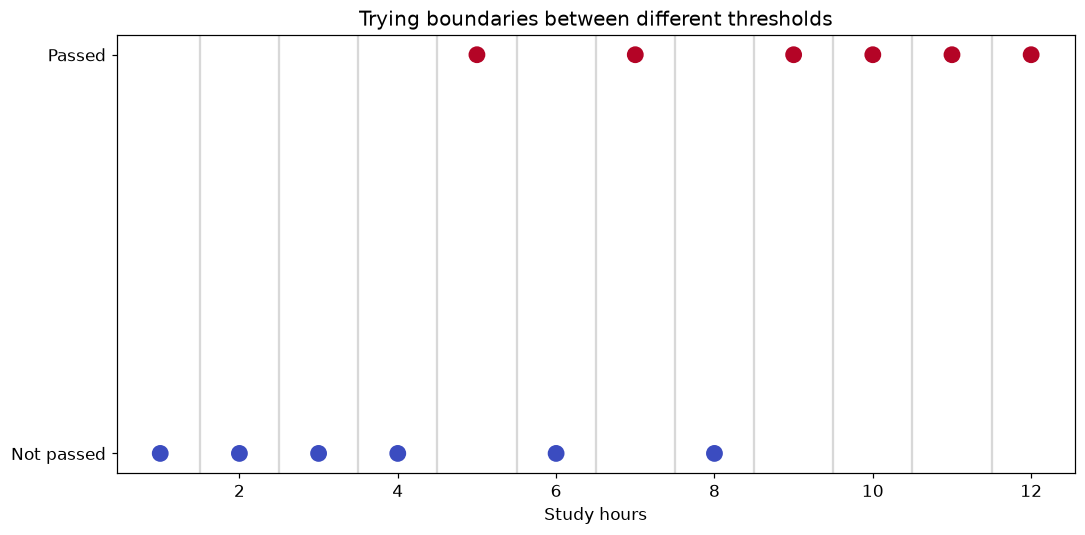

In [52]:
plt.figure(figsize = (10,5))
plt.scatter(Xe.hours, ye, c = ye, cmap = 'coolwarm', s=100)
for t in thresholds:
    plt.axvline(t, color = 'grey', alpha = 0.3)

plt.yticks([0,1], ['Not passed', 'Passed'])
plt.xlabel("Study hours")
plt.title("Trying boundaries between different thresholds")
plt.tight_layout()
plt.show()

In [53]:
gini(0.75)

0.375

In [54]:
gini(1)

0

In [55]:
entropy(0.5)

np.float64(1.0)

## Calculate gini reduction for each threshold

In [56]:
def gini(labels):
    _, counts = np.unique(labels, return_counts=True)
    p = counts / counts.sum()
    return 1 - np.sum(p**2)

rows = []
for t in thresholds:
    left = ye[Xe.hours <= t]
    right = ye[Xe.hours > t]
    child = (len(left)*gini(left) + len(right)*gini(right)) / len(ye)
    rows.append([t, len(left), len(right), child, gini(ye)-child])

split_table = pd.DataFrame(rows, columns = [
    'threshold', 'n_left', 'n_right', 'child_gini', 'gini_decrease'
])

print(split_table.round(4).to_string(index = False))






 threshold  n_left  n_right  child_gini  gini_decrease
       1.5       1       11      0.4545         0.0455
       2.5       2       10      0.4000         0.1000
       3.5       3        9      0.3333         0.1667
       4.5       4        8      0.2500         0.2500
       5.5       5        7      0.3714         0.1286
       6.5       6        6      0.2778         0.2222
       7.5       7        5      0.3714         0.1286
       8.5       8        4      0.2500         0.2500
       9.5       9        3      0.3333         0.1667
      10.5      10        2      0.4000         0.1000
      11.5      11        1      0.4545         0.0455


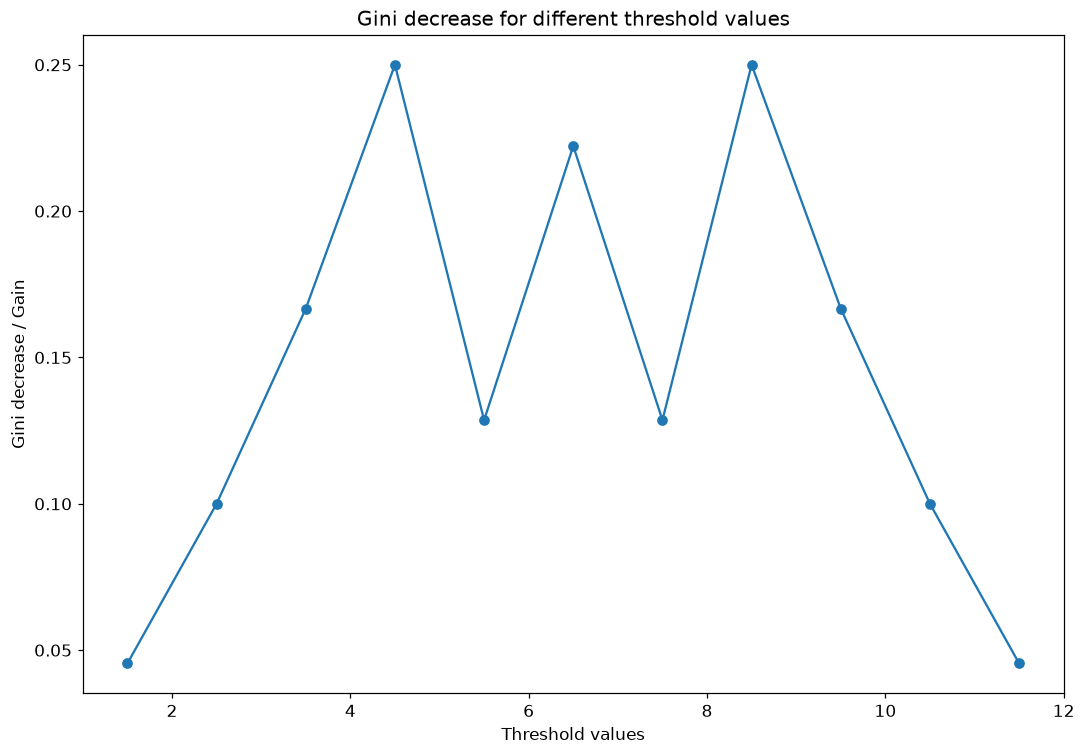

In [57]:
plt.figure(figsize = (10,7))
plt.plot(split_table.threshold, split_table.gini_decrease, 'o-')
plt.xlabel('Threshold values')
plt.ylabel('Gini decrease / Gain')
plt.title("Gini decrease for different threshold values")
plt.tight_layout()
plt.show()


In [58]:
tree = DecisionTreeClassifier(max_depth = 1, random_state=42)
tree.fit(Xe[['hours']], ye)
print('Tree threshold value: ', tree.tree_.threshold[0])


Tree threshold value:  4.5


In [59]:
print("Tree root gini: ", tree.tree_.impurity[0])

Tree root gini:  0.5


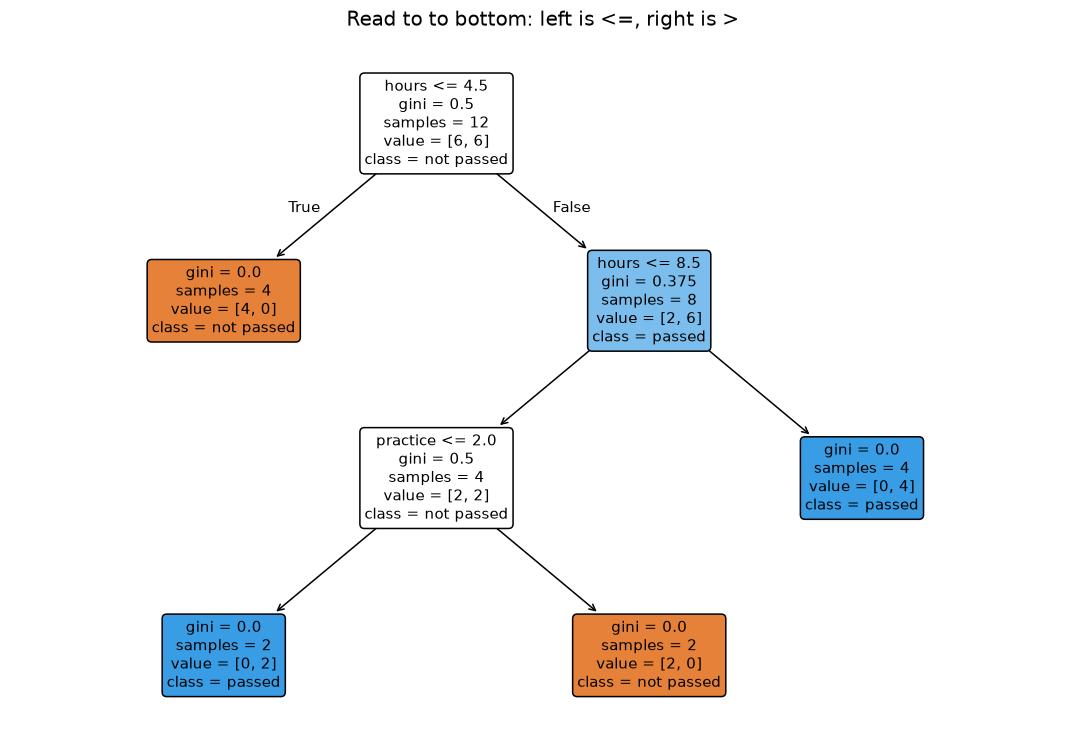

|--- hours <= 4.50
|   |--- class: 0
|--- hours >  4.50
|   |--- hours <= 8.50
|   |   |--- practice <= 2.00
|   |   |   |--- class: 1
|   |   |--- practice >  2.00
|   |   |   |--- class: 0
|   |--- hours >  8.50
|   |   |--- class: 1



In [60]:
exam_tree = DecisionTreeClassifier(max_depth = 3, random_state=42)
exam_tree.fit(Xe, ye)
plt.figure(figsize=(10,7))
plot_tree(exam_tree, feature_names=list(Xe.columns),
          class_names=['not passed', 'passed'],
          filled = True, rounded=True, fontsize=10)
plt.title("Read to to bottom: left is <=, right is >")
plt.tight_layout()
plt.show()
print(export_text(exam_tree, feature_names = list(Xe.columns)))

Root entropy:  1.0
Gain at 4.5:  0.4591479170272448


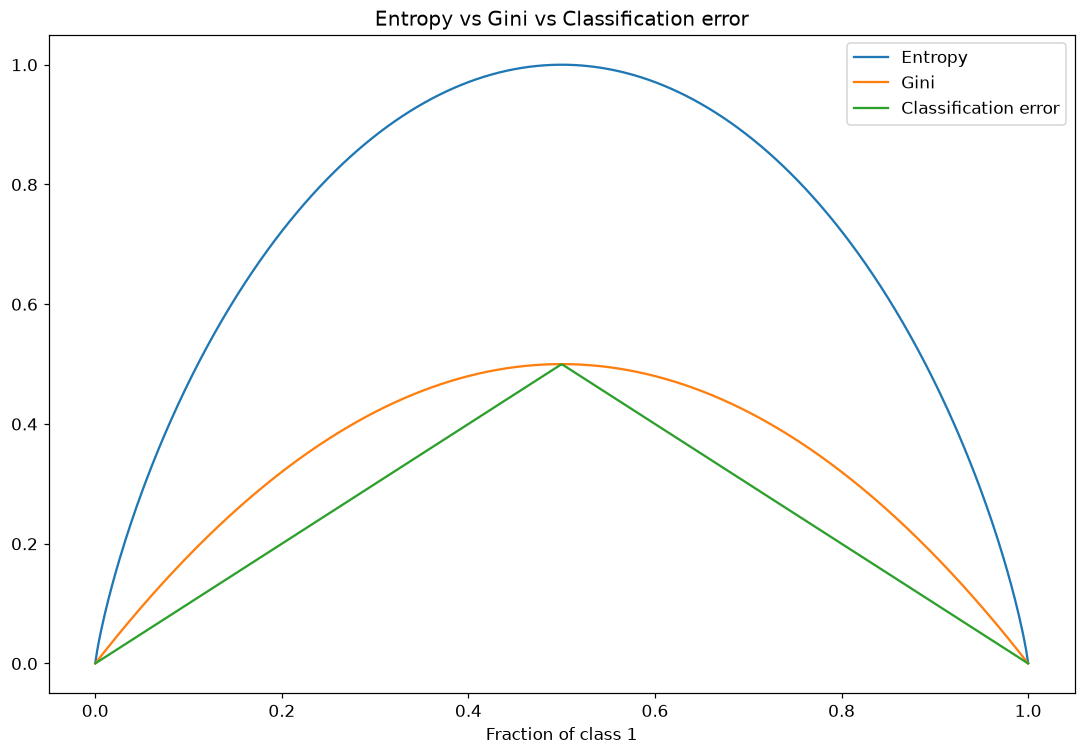

In [64]:
def entropy(labels):
    _, counts = np.unique(labels, return_counts=True)
    p = counts / counts.sum()
    return -(np.sum(p*np.log2(p)))

p = np.linspace(0.0001, 0.9999, 500)
h = -p*np.log2(p) - (1-p)*np.log2(1-p)
plt.figure(figsize=(10,7))
plt.plot(p, h, label = 'Entropy')
plt.plot(p, 2*p*(1-p), label = 'Gini')
plt.plot(p, np.minimum(p, 1-p), label = 'Classification error')
plt.xlabel('Fraction of class 1')
plt.title("Entropy vs Gini vs Classification error")
plt.legend()
plt.tight_layout()
print("Root entropy: ", entropy(ye))
print("Gain at 4.5: ", 1-(8/12) * entropy(ye[Xe.hours > 4.5]))



In [65]:
new_row = pd.DataFrame({'hours': [6], 'practice': [2]})
print("Class order: ", exam_tree.classes_)

Class order:  [0 1]


In [66]:
print("Prediction: ", exam_tree.predict(new_row))

Prediction:  [1]


In [67]:
print("Probabilities: ", exam_tree.predict_proba(new_row))

Probabilities:  [[0. 1.]]


In [72]:
exam_tree.predict_proba(new_row).shape

(1, 2)

In [68]:
print("Leaf id: ", exam_tree.apply(new_row))

Leaf id:  [4]


In [74]:
path_nodes = exam_tree.decision_path(new_row).indices
print(path_nodes)

[0 2 3 4]


In [78]:
exam_tree.tree_.feature

array([ 0, -2,  0,  1, -2, -2, -2])

hours <= 4.5 : False
hours <= 8.5 : True
practice <= 2.0 : True


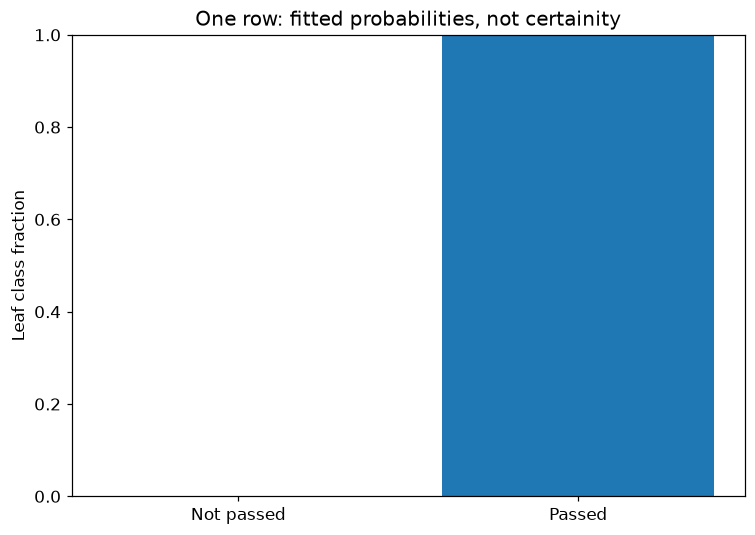

In [73]:
for node in path_nodes:
    feature = exam_tree.tree_.feature[node]
    if feature >= 0:
        name = Xe.columns[feature]
        threshold = exam_tree.tree_.threshold[node]
        print(name, "<=", round(threshold,3),
              ":", new_row.iloc[0, feature] <= threshold)

plt.figure(figsize=(7,5))
plt.bar(['Not passed', 'Passed'], exam_tree.predict_proba(new_row)[0])
plt.ylim(0, 1)
plt.ylabel("Leaf class fraction")
plt.title("One row: fitted probabilities, not certainity")
plt.tight_layout()
plt.show()

In [87]:
Xe.columns[0]

'hours'

## The IRIS dataset

In [92]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)

iris


{'data':      sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
 0                  5.1               3.5                1.4               0.2
 1                  4.9               3.0                1.4               0.2
 2                  4.7               3.2                1.3               0.2
 3                  4.6               3.1                1.5               0.2
 4                  5.0               3.6                1.4               0.2
 ..                 ...               ...                ...               ...
 145                6.7               3.0                5.2               2.3
 146                6.3               2.5                5.0               1.9
 147                6.5               3.0                5.2               2.0
 148                6.2               3.4                5.4               2.3
 149                5.9               3.0                5.1               1.8
 
 [150 rows x 4 columns],
 'target': 0     

In [93]:
X = iris.data[['petal length (cm)', 'petal width (cm)']]

y = iris.target

In [94]:
Xs, Xtest, ys, ytest= train_test_split(
    X, y, test_size = 0.2, stratify=y, random_state=42
)

Xtr, Xval, ytr, yval = train_test_split(
    Xs, ys, test_size=0.25, stratify=ys, random_state=42
)

print("train validation, test: ", len(Xtr), len(Xval), len(Xtest))

train validation, test:  90 30 30


In [97]:
print("Classes: ", dict(enumerate(iris.target_names)))

Classes:  {0: np.str_('setosa'), 1: np.str_('versicolor'), 2: np.str_('virginica')}


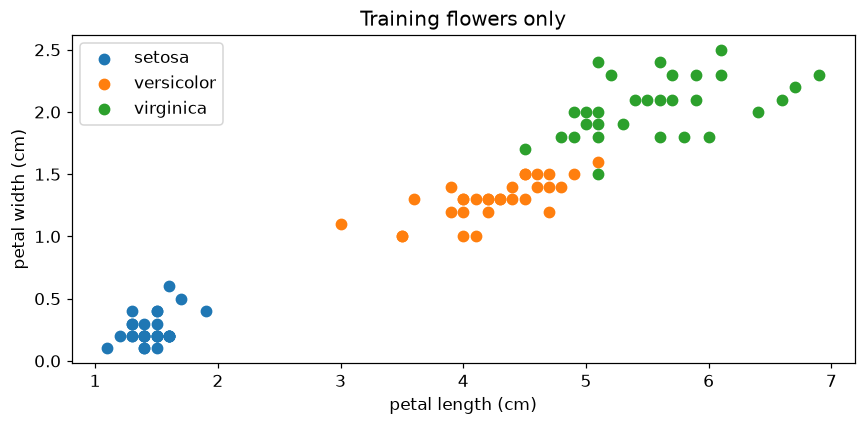

In [98]:
plt.figure(figsize = (8,4))
for k, name in enumerate(iris.target_names):
    rows = ytr == k
    plt.scatter(Xtr.loc[rows].iloc[:,0],
                Xtr.loc[rows].iloc[:,1], label = name, s =45)

plt.xlabel(X.columns[0])
plt.ylabel(X.columns[1])
plt.legend()
plt.title("Training flowers only")
plt.tight_layout()
plt.show()

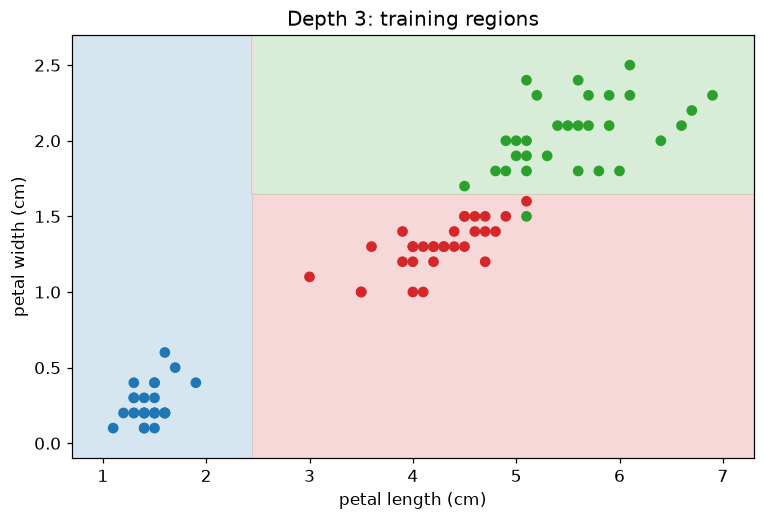

In [105]:
iris_tree = DecisionTreeClassifier(max_depth = 3, random_state=42)
iris_tree.fit(Xtr, ytr)
fig, ax = plt.subplots(figsize = (8,5))


def boundary(model, features, target, ax, title):
    a = np.linspace(features.iloc[:,0].min()- 0.4,
                    features.iloc[:,0].max() + 0.4, 180)
    b = np.linspace(features.iloc[:,1].min()- 0.2,
                    features.iloc[:,1].max() + 0.2, 180)

    xx, yy = np.meshgrid(a, b)

    grid = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()],
                        columns = features.columns)
    cmap = ListedColormap(['tab:blue', 'tab:red', 'tab:green'])
    zz = model.predict(grid).reshape(xx.shape)
    
    ax.contourf(xx, yy, zz, levels = [-.5, .5, 1.5, 2.5],
                cmap = cmap, alpha = 0.18)
    ax.scatter(features.iloc[:,0], features.iloc[:,1],
               c=target, cmap = cmap, vmin=0, vmax=2)
    ax.set(xlabel=features.columns[0],ylabel = features.columns[1],
           title = title)
    
boundary(iris_tree, Xtr, ytr, ax, "Depth 3: training regions")

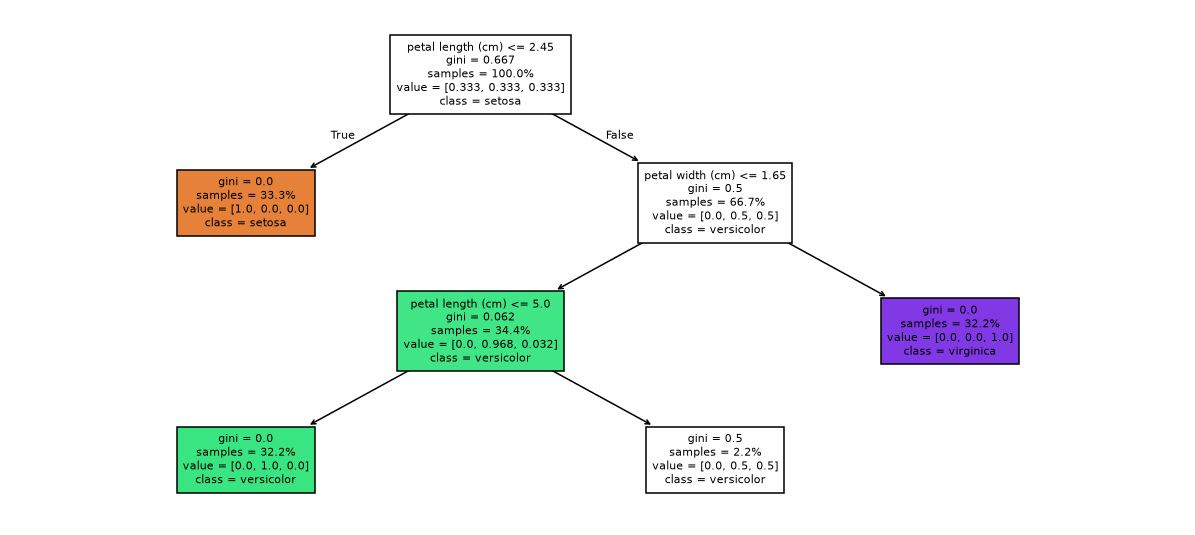

4
Depth:  3 Leaves:  4


In [117]:
plt.figure(figsize=(11,5))
plot_tree(iris_tree, feature_names=list(X.columns),
          class_names=list(iris.target_names), filled = True,
          rounded = False, proportion=True, fontsize=7)
plt.tight_layout()
plt.show()

tr = iris_tree.tree_

nodes = pd.DataFrame({
    'left': tr.children_left, 'right': tr.children_right,
    'feature': tr.feature, 'threshold': tr.threshold,
    'impurity': tr.impurity, 'rows': tr.n_node_samples
})

print(node.round(3))
print("Depth: ", iris_tree.get_depth(), 'Leaves: ', iris_tree.get_n_leaves())

## Overfitting, bias and variance in decision trees

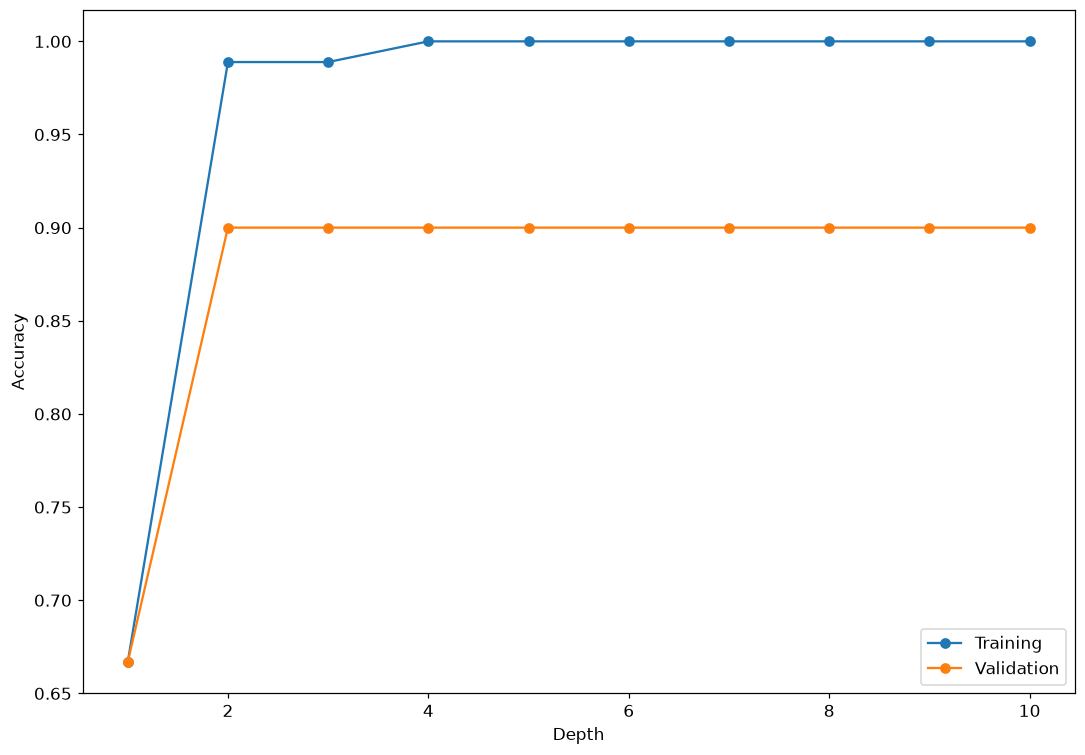

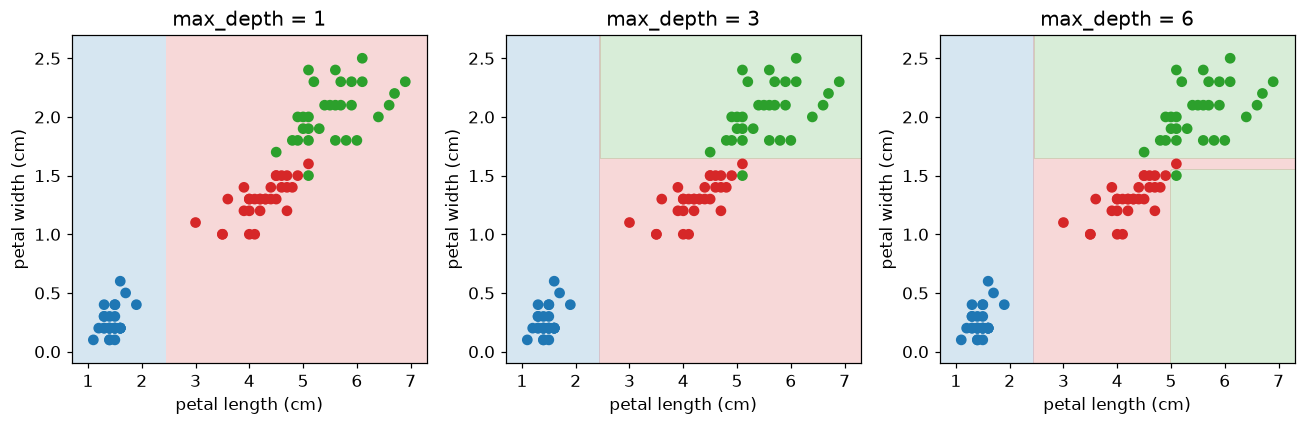

In [122]:
depths = list(range(1,11))

train_scores, val_scores = [], []

for d in depths: 
    model = DecisionTreeClassifier(max_depth = d, random_state=42)
    model.fit(Xtr, ytr)
    train_scores.append(model.score(Xtr, ytr))
    val_scores.append(model.score(Xval, yval))

plt.figure(figsize=(10,7))
plt.plot(depths, train_scores, 'o-', label='Training')
plt.plot(depths, val_scores, 'o-', label = 'Validation')
plt.xlabel('Depth')
plt.ylabel('Accuracy')
plt.legend()
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(1, 3, figsize = (12, 4))
for ax, d in zip(axes, [1,3,6]):
    model = DecisionTreeClassifier(max_depth=d, random_state=42).fit(Xtr, ytr)
    boundary(model, Xtr, ytr, ax, f'max_depth = {d}')
plt.tight_layout()
plt.show()

1 leaves:  5 validation: 0.9
5 leaves:  4 validation: 0.9
15 leaves:  4 validation: 0.9


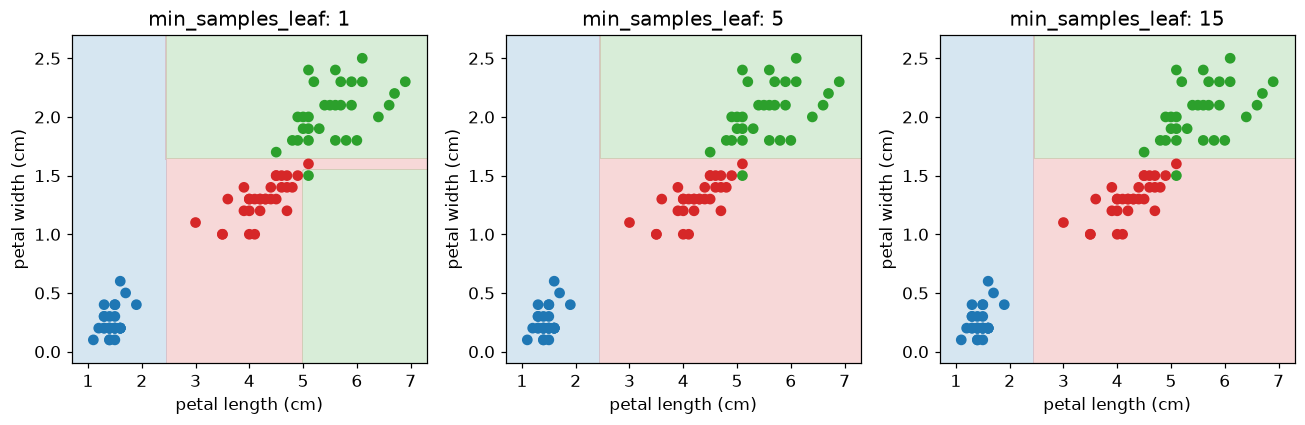

In [123]:
fig, axes = plt.subplots(1, 3, figsize = (12,4))

for ax, leaf_size in zip(axes, [1,5,15]):
    model = DecisionTreeClassifier(
        min_samples_leaf=leaf_size, random_state=42).fit(Xtr, ytr)
    boundary(model, Xtr, ytr, ax, f'min_samples_leaf: {leaf_size}')
    print(leaf_size, 'leaves: ', model.get_n_leaves(),
          'validation:', round(model.score(Xval, yval), 3))

plt.tight_layout()
plt.show()

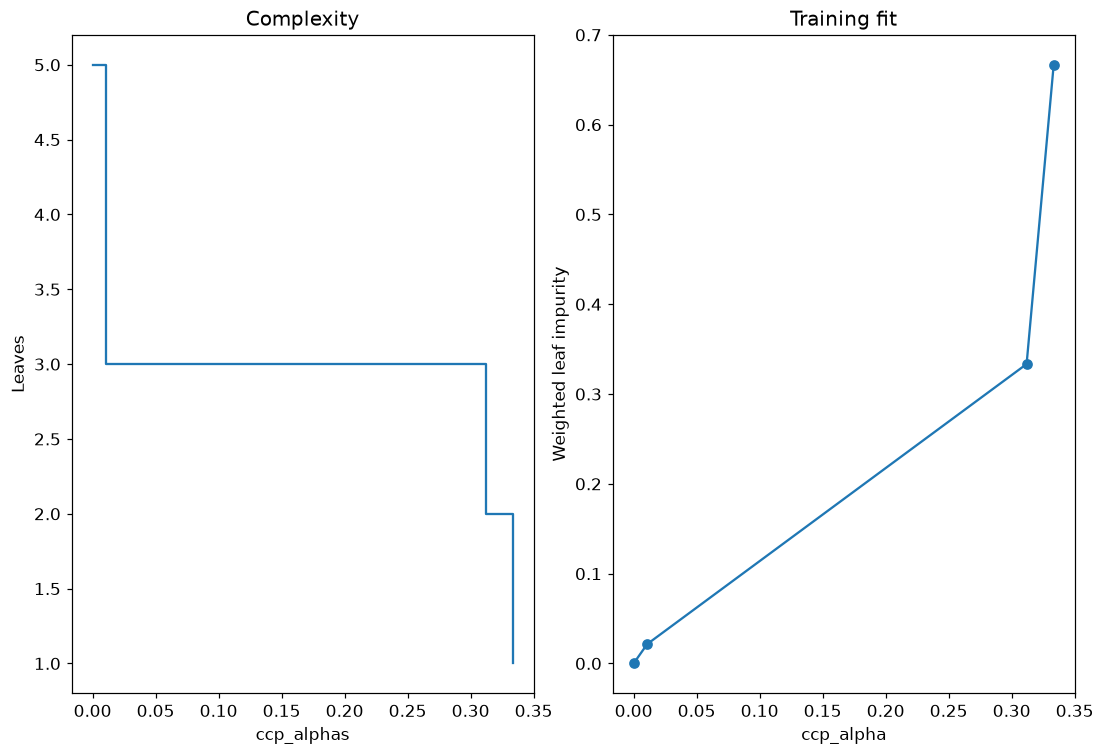

In [124]:
grown = DecisionTreeClassifier(random_state=42).fit(Xtr, ytr)
path = grown.cost_complexity_pruning_path(Xtr, ytr)
leaves = []
for alpha in path.ccp_alphas:
    model = DecisionTreeClassifier(ccp_alpha=alpha, random_state=42)
    model.fit(Xtr, ytr)
    leaves.append(model.get_n_leaves())

fig, axes = plt.subplots(1, 2, figsize=(10, 7))
axes[0].step(path.ccp_alphas, leaves, where = 'post')
axes[0].set(xlabel = 'ccp_alphas', ylabel = 'Leaves', title = 'Complexity')
axes[1].plot(path.ccp_alphas, path.impurities, 'o-')
axes[1].set(xlabel = 'ccp_alpha', ylabel = 'Weighted leaf impurity',
            title = 'Training fit')
plt.tight_layout()
plt.show()


selected:  {'ccp_alpha': 0.0, 'max_depth': 3, 'min_samples_leaf': 3}
Mean cv accuracy:  0.9667
   param_max_depth  param_min_samples_leaf  param_ccp_alpha  mean_test_score
7                5                       3             0.00         0.966667
4                3                       3             0.00         0.966667
15               3                       1             0.01         0.966667
10            None                       3             0.00         0.966667
19               5                       3             0.01         0.966667
22            None                       3             0.01         0.966667
16               3                       3             0.01         0.966667
8                5                       6             0.00         0.958333
17               3                       6             0.01         0.958333
11            None                       6             0.00         0.958333


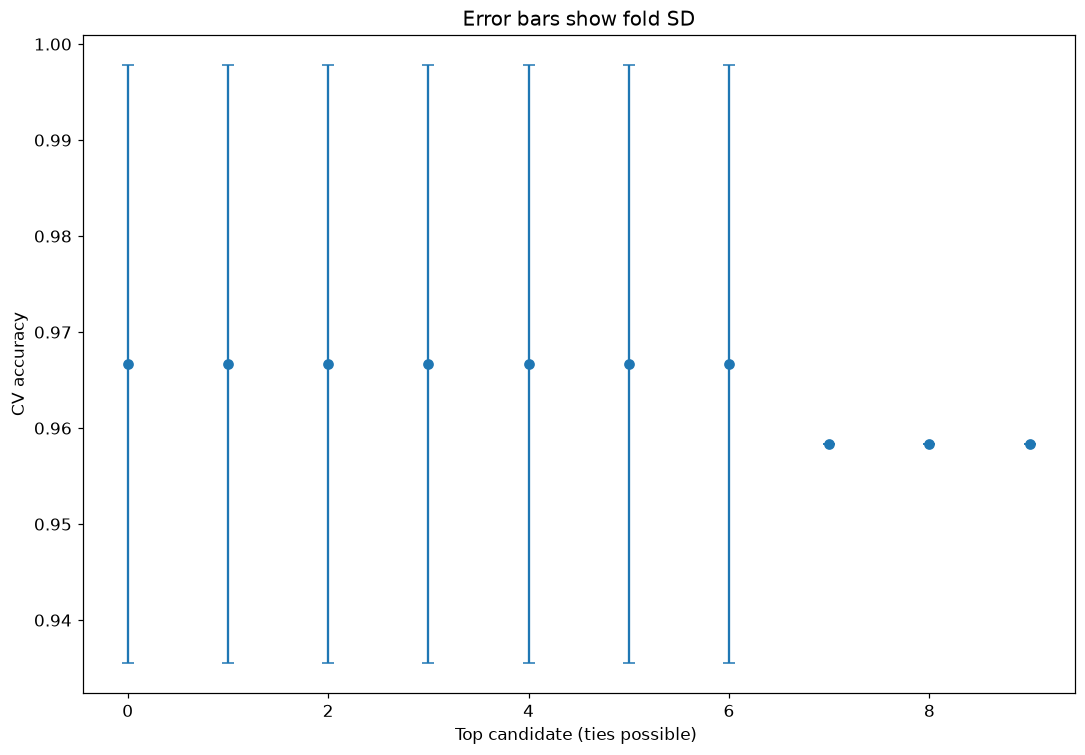

In [125]:
cv = StratifiedKFold(n_splits = 5, shuffle=True, random_state=42)
grid = {
    'max_depth': [2,3,5,None],
    'min_samples_leaf': [1,3,6],
    'ccp_alpha': [0.0, 0.01, 0.03]
}

search = GridSearchCV(
    DecisionTreeClassifier(random_state=42), grid, 
    scoring = 'accuracy', cv=cv, n_jobs=-1, return_train_score=True
)

search.fit(Xs, ys)
best = search.best_estimator_
print("selected: ", search.best_params_)
print("Mean cv accuracy: ", round(search.best_score_, 4))
results = pd.DataFrame(
    search.cv_results_
)

top = results.sort_values('rank_test_score').head(10)

print(top[['param_max_depth', 'param_min_samples_leaf',
          'param_ccp_alpha', 'mean_test_score']])

plt.figure(figsize=(10,7))
plt.errorbar(range(len(top)), top.mean_test_score,
             yerr = top.std_test_score, fmt='o', capsize=4)
plt.xlabel('Top candidate (ties possible) ')
plt.ylabel("CV accuracy")
plt.title("Error bars show fold SD")
plt.tight_layout()
plt.show()


## Accuracy, precision, recall and F1

Final test rows:  30
Tree accuracy:  0.9666666666666667
Baseline accuracy:  0.3333333333333333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



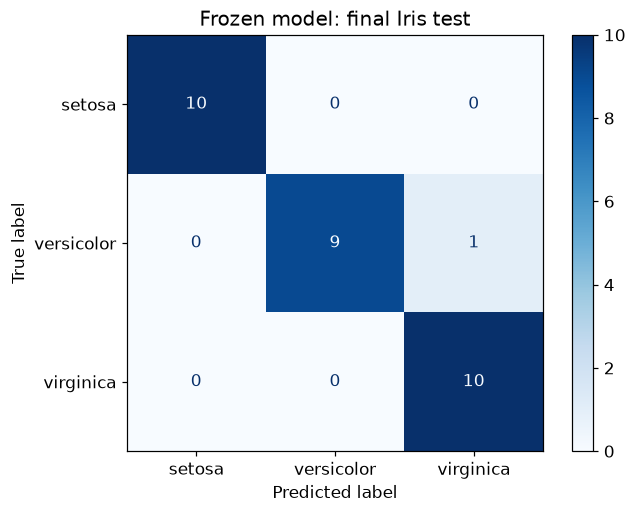

In [126]:
from sklearn.dummy import DummyClassifier

pred = best.predict(Xtest)
baseline = DummyClassifier(strategy='most_frequent').fit(Xs, ys)
print("Final test rows: ", len(ytest))
print("Tree accuracy: ", accuracy_score(ytest, pred))
print("Baseline accuracy: ", baseline.score(ytest, pred))
print(classification_report(ytest, pred, 
                            target_names=iris.target_names, zero_division=0))
ConfusionMatrixDisplay.from_predictions(
    ytest, pred, display_labels=iris.target_names, cmap='Blues'
)
plt.title("Frozen model: final Iris test")
plt.tight_layout()
plt.show()


## Regression leaves

In [ ]:
rng = np.random.default_rng(42)
temperature = np.linspace(15, 40, 120)
true_sales = 35 + 3*(temperature - 15) + 35*(temperature>28)

sales = true_sales + rng.normal(0, 8, len(temperature))

sales_df = pd.DataFrame({'temperature': temperature, 'sales': sales})


Xs, ys= sales_df[['temperature']], sales_df.sales

Xsdev, Xstest, ysdev, ystest = train_test_split(
    Xs, ys, test_size=0.2, random_state=42
)

Xsr, Xsv, ysr, ysv = train_test_split(
    Xsdev, ysdev, test_size=0.25, random_state=42

)